# Hospital Readmission Risk Prediction Using an MLP
**Deep Learning – Industry Mini Use Case (Healthcare)** · TensorFlow / Keras (Sequential API)
**Dataset:** Diabetes 130-US Hospitals (1999–2008) · **Task:** binary classification – readmitted within 30 days
**Methodology:** CBIM (Business understanding → DL problem → Data → MLP → Evaluation → Error analysis → Business insights)

> ⚠️ **Precaution:** The data is historical (1999–2008) and this model is an **educational prototype**, not a clinically validated decision-making system.

**Notebook map**

| Part | CBIM stage | Marks area |
|---|---|---|
| 1 | Business understanding & problem identification | CBIM & business understanding (15) |
| 2 | Translating the business problem into a deep-learning problem | CBIM (15) |
| 3 | Data understanding & preparation | Exploration & preprocessing (15) |
| 4 | MLP architecture design & implementation | Architecture (20) + Keras concepts (15) |
| 5 | Model training & evaluation | Evaluation (15) |
| 6 | Structured error analysis | Error analysis (10) |
| 7 | Business insights & recommendations | Recommendations (10) |

---
# Part 1 · Business Understanding & Problem Identification

**Problem.** Patients who return to hospital shortly after discharge increase operating cost, occupy scarce beds and often signal that discharge planning or follow-up care was insufficient.

**Business question.** *Which patients are at higher risk of being readmitted within 30 days of discharge, so that management can target discharge planning, follow-up appointments and post-discharge support at them?*

**Business objectives**
1. Identify patients at risk of readmission within 30 days.
2. Understand which patient and encounter characteristics are associated with readmission.
3. Build an MLP using TensorFlow/Keras.
4. Evaluate it with classification metrics (accuracy, precision, recall, F1, ROC-AUC).
5. Perform structured error analysis (false positives / false negatives).
6. Recommend strategies to improve post-discharge patient management.

**Why a missed high-risk patient is costly (false negative).** An unflagged patient who is readmitted incurs an avoidable admission cost, takes a bed from another patient, may suffer a clinical deterioration that earlier follow-up could have caught, and (in many payment systems) can trigger readmission penalties. A false alarm (false positive), by contrast, usually costs only a phone call or an earlier follow-up appointment. **The two errors are therefore asymmetric, which is why we will look beyond accuracy and tune the decision threshold for recall.**

---
# Part 2 · Translating the Business Problem into a Deep-Learning Problem

| Business view | Deep-learning view |
|---|---|
| "Will this patient come back within 30 days?" | **Supervised binary classification** on tabular data |
| Patient encounter at discharge | One row = one encounter; features are known **at discharge time** |
| Readmitted `<30` | Label **1** |
| Readmitted `>30` or `NO` | Label **0** |
| Risk score for prioritising follow-up | Sigmoid output = predicted probability of readmission |
| Cost of a missed patient ≫ cost of a false alarm | Class weights + decision-threshold tuning, judged with recall / F1 / ROC-AUC / PR-AUC rather than accuracy |

**Model choice:** Multi-Layer Perceptron – `Dense(ReLU)` hidden layers → `Dense(1, sigmoid)`, compiled with **Adam** and **binary cross-entropy**.

**Key industry challenges we must handle explicitly:** class imbalance · missing values · data leakage · generalization (train vs validation gap) · business impact.

---
# Part 3 · Data Understanding & Preparation


In [13]:
import os, csv, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.utils.class_weight import compute_class_weight
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             roc_curve, precision_recall_curve)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
print("TensorFlow:", tf.__version__)

TensorFlow: 2.19.0


In [14]:
# Locate the data files (edit DATA_DIR if your files are elsewhere)
CANDIDATES = [".", "data", "/mnt/user-data/uploads", "/content", "/content/drive/MyDrive"]
DATA_DIR = next((d for d in CANDIDATES if os.path.exists(os.path.join(d, "diabetic_data.csv"))), None)
assert DATA_DIR is not None, "diabetic_data.csv not found - set DATA_DIR manually"
print("Using data from:", os.path.abspath(DATA_DIR))

# '?' is the dataset's marker for missing values.
# keep_default_na=False so the legitimate category 'None' (test not performed) is NOT turned into NaN.
raw = pd.read_csv(os.path.join(DATA_DIR, "diabetic_data.csv"), na_values="?", keep_default_na=False, na_filter=True)
raw = raw.replace("", np.nan)
print("Shape:", raw.shape)
raw.head()

Using data from: c:\Users\Dell\Downloads\diabetes+130-us+hospitals+for+years+1999-2008
Shape: (101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,NaN,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,NaN,NaN,1,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,NaN,NaN,59,0,18,0,0,0,276,250.01,255,9,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,NaN,NaN,11,5,13,2,0,1,648,250,V27,6,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,NaN,NaN,44,1,16,0,0,0,8,250.43,403,7,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,NaN,NaN,51,0,8,0,0,0,197,157,250,5,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


### Reading the ID-mapping file
`IDS_mapping.csv` contains **three** lookup tables stacked in one file (admission type, discharge disposition, admission source). We parse them so that the numeric IDs can be interpreted and grouped sensibly.

In [15]:
def load_ids_mapping(path):
    mappings, key = {}, None
    with open(path, newline="", encoding="utf-8-sig") as f:
        for row in csv.reader(f):
            if not row or all(c.strip() == "" for c in row):
                key = None; continue
            if row[0] in ("admission_type_id", "discharge_disposition_id", "admission_source_id"):
                key = row[0]; mappings[key] = {}; continue
            if key: mappings[key][int(row[0])] = row[1].strip()
    return mappings

ids_map = load_ids_mapping(os.path.join(DATA_DIR, "IDS_mapping.csv"))
for k, v in ids_map.items():
    print(f"{k}: {len(v)} codes")
pd.Series(ids_map["discharge_disposition_id"], name="description").to_frame().head(12)

admission_type_id: 8 codes
discharge_disposition_id: 30 codes
admission_source_id: 25 codes


,description
1,Discharged to home
2,Discharged/transferred to another short term h...
3,Discharged/transferred to SNF
4,Discharged/transferred to ICF
5,Discharged/transferred to another type of inpa...
6,Discharged/transferred to home with home healt...
7,Left AMA
8,Discharged/transferred to home under care of H...
9,Admitted as an inpatient to this hospital
10,Neonate discharged to another hospital for neo...


## 3.2 Data understanding – shape, info, statistics, missing values, duplicates

In [16]:
print("Rows, columns:", raw.shape)
raw.info()

Rows, columns: (101766, 50)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      99493 non-null   object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    3197 non-null    object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                61510 non-null   object
 11  medical_specialty         51817 non-null   object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            10176

In [17]:
num_summary = raw.describe().T
num_summary

,count,mean,std,min,25%,50%,75%,max
encounter_id,101766.0,1.652016e+08,1.026403e+08,12522.0,84961194.0,152388987.0,2.302709e+08,443867222.0
patient_nbr,101766.0,5.433040e+07,3.869636e+07,135.0,23413221.0,45505143.0,8.754595e+07,189502619.0
admission_type_id,101766.0,2.024006e+00,1.445403e+00,1.0,1.0,1.0,3.000000e+00,8.0
discharge_disposition_id,101766.0,3.715642e+00,5.280166e+00,1.0,1.0,1.0,4.000000e+00,28.0
admission_source_id,101766.0,5.754437e+00,4.064081e+00,1.0,1.0,7.0,7.000000e+00,25.0
time_in_hospital,101766.0,4.395987e+00,2.985108e+00,1.0,2.0,4.0,6.000000e+00,14.0
num_lab_procedures,101766.0,4.309564e+01,1.967436e+01,1.0,31.0,44.0,5.700000e+01,132.0
num_procedures,101766.0,1.339730e+00,1.705807e+00,0.0,0.0,1.0,2.000000e+00,6.0
num_medications,101766.0,1.602184e+01,8.127566e+00,1.0,10.0,15.0,2.000000e+01,81.0
number_outpatient,101766.0,3.693572e-01,1.267265e+00,0.0,0.0,0.0,0.000000e+00,42.0


In [18]:
# Categorical summary (cardinality and most frequent value)
cat_cols_raw = raw.select_dtypes(include="object").columns
pd.DataFrame({
    "n_unique": raw[cat_cols_raw].nunique(),
    "top_value": raw[cat_cols_raw].mode().iloc[0],
    "top_share_%": [round(raw[c].value_counts(normalize=True).iloc[0]*100, 1) for c in cat_cols_raw],
}).sort_values("n_unique", ascending=False)

,n_unique,top_value,top_share_%
diag_3,789,250,11.5
diag_2,748,276,6.7
diag_1,716,428,6.7
medical_specialty,72,InternalMedicine,28.2
payer_code,17,MC,52.7
age,10,[70-80),25.6
weight,9,[75-100),41.8
race,5,Caucasian,76.5
glyburide-metformin,4,No,99.3
max_glu_serum,4,None,94.7


In [19]:
# Duplicates
print("Fully duplicated rows        :", raw.duplicated().sum())
print("Duplicated encounter_id      :", raw["encounter_id"].duplicated().sum())
print("Unique patients (patient_nbr):", raw["patient_nbr"].nunique(), "of", len(raw), "encounters")
print("Patients with >1 encounter   :", (raw["patient_nbr"].value_counts() > 1).sum())

Fully duplicated rows        : 0
Duplicated encounter_id      : 0
Unique patients (patient_nbr): 71518 of 101766 encounters
Patients with >1 encounter   : 16773


**Observations**
- No exact duplicate rows or duplicated encounters, **but ~71.5k patients account for ~101.8k encounters** – many patients appear several times. If we split rows randomly, the same patient could land in both train and test and the model could "memorise" the patient. We will therefore **split by patient** (Section 3.8).
- Several columns are constant or almost constant (e.g. `examide`, `citoglipton`) – we will check and drop them.

## 3.3 Target variable & class imbalance

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64


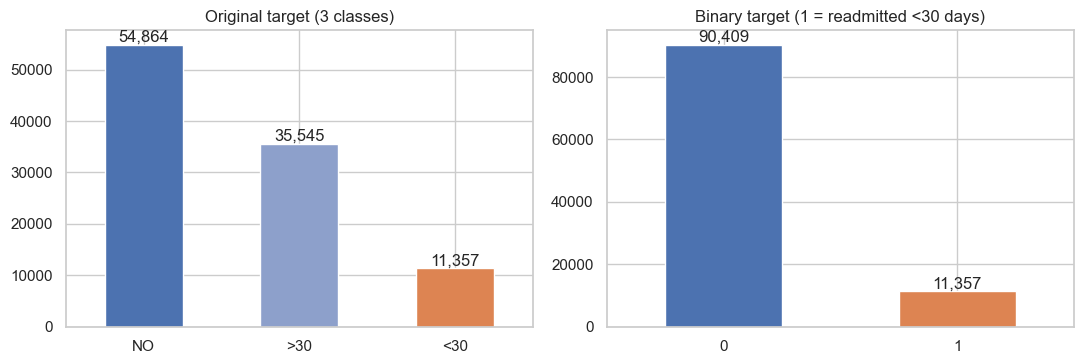

Positive rate (<30 days): 11.16%  |  imbalance ratio ≈ 1 : 8.0
A model that ALWAYS predicts 'not readmitted' would score 88.84% accuracy while catching 0% of readmissions.


In [20]:
print(raw["readmitted"].value_counts())
raw["target"] = (raw["readmitted"] == "<30").astype(int)   # 1 = readmitted within 30 days, 0 = '>30' or 'NO'

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
raw["readmitted"].value_counts().reindex(["NO", ">30", "<30"]).plot.bar(ax=ax[0], color=["#4C72B0", "#8da0cb", "#DD8452"])
ax[0].set_title("Original target (3 classes)"); ax[0].set_xlabel(""); ax[0].tick_params(axis="x", rotation=0)
raw["target"].value_counts().sort_index().plot.bar(ax=ax[1], color=["#4C72B0", "#DD8452"])
ax[1].set_title("Binary target (1 = readmitted <30 days)"); ax[1].set_xlabel(""); ax[1].tick_params(axis="x", rotation=0)
for a in ax:
    for p in a.patches:
        a.annotate(f"{int(p.get_height()):,}", (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")
plt.tight_layout(); plt.show()

pos_rate = raw["target"].mean()
print(f"Positive rate (<30 days): {pos_rate:.2%}  |  imbalance ratio ≈ 1 : {(1-pos_rate)/pos_rate:.1f}")
print(f"A model that ALWAYS predicts 'not readmitted' would score {1-pos_rate:.2%} accuracy while catching 0% of readmissions.")

**Class-imbalance finding.** Patients readmitted within 30 days are a **small minority (~11%)**. Consequences:
- **Accuracy is misleading** – a useless "always No" model already scores ~89%.
- An unweighted network is pulled toward the majority class and tends to have **very low recall** for the class the hospital cares about.
- **Our response:** (i) judge models with recall, precision, F1, ROC-AUC and PR-AUC; (ii) use **class weights** in the loss (and compare against no weighting); (iii) **tune the decision threshold** on the validation set; (iv) use **stratified** splits so all sets keep the same positive rate.

## 3.4 Missing values

,missing_count,missing_%
weight,98569,96.86
medical_specialty,49949,49.08
payer_code,40256,39.56
race,2273,2.23
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02


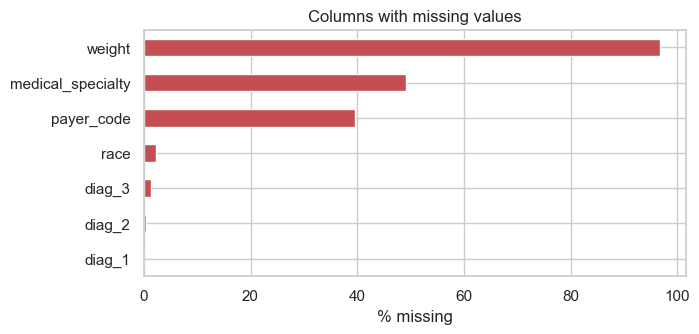

{'None': 96420, 'Norm': 2597, '>200': 1485, '>300': 1264}
{'None': 84748, '>8': 8216, 'Norm': 4990, '>7': 3812}


In [21]:
miss = pd.DataFrame({
    "missing_count": raw.isna().sum(),
    "missing_%": (raw.isna().mean()*100).round(2),
})
miss = miss[miss["missing_count"] > 0].sort_values("missing_%", ascending=False)
display(miss)

ax = miss["missing_%"].plot.barh(figsize=(7, 3.2), color="#C44E52")
ax.set_xlabel("% missing"); ax.set_title("Columns with missing values"); ax.invert_yaxis(); plt.show()

# 'None' in these two columns means 'test not performed' (a real category, not missing data)
print(raw["max_glu_serum"].value_counts().to_dict())
print(raw["A1Cresult"].value_counts().to_dict())

**Treatment & justification**

| Column | Missing | Decision | Why |
|---|---|---|---|
| `weight` | ~97% | **Drop** | Almost never recorded – imputing 97% of a column would just invent data. |
| `medical_specialty` | ~49% | Keep as a category **"Unknown"** | Missingness itself is informative (specialty often not recorded); rare specialties are merged into "infrequent" by the encoder. |
| `payer_code` | ~40% | Keep as category **"Unknown"** | Same reasoning; insurance type can relate to follow-up access. |
| `race` | ~2% | Category **"Unknown"** | Small share; avoids dropping rows or guessing. |
| `diag_1/2/3` | <1.5% | Category **"Unknown"** (after grouping to ICD-9 families) | A missing secondary/tertiary diagnosis usually means "no further diagnosis". |
| `max_glu_serum`, `A1Cresult` | (read as category `None`) | Keep **"None" = test not performed** | A clinically meaningful category, not a gap. |
| `gender` = "Unknown/Invalid" | 3 rows | **Drop rows** | Negligible and invalid. |

## 3.5 Data leakage – only use information available **at discharge**

Leakage means the model sees information that would not exist when the prediction is actually needed (at discharge), which gives deceptively good results. Our checks:

| Item | Verdict | Action |
|---|---|---|
| `encounter_id`, `patient_nbr` | Identifiers, not clinical signals (and `encounter_id` can encode time ordering) | **Removed from features**; kept aside only to label the final report and to split by patient |
| Patients who **died or went to hospice** (discharge IDs 11, 13, 14, 19, 20, 21) | They *cannot* be readmitted, so they would be "easy negatives" that distort the label and the metrics | **Rows removed** |
| `number_outpatient / emergency / inpatient` | Visits in the **year before** the encounter | Safe – known at discharge (and strong predictors) |
| `diag_1–3`, medications, lab tests, `time_in_hospital`, `discharge_disposition_id` | All recorded **during** the stay and available at discharge | Safe |
| The same patient in train *and* test | Memorisation risk | **Patient-level split** |
| Scaler / encoder fitted on all data | Statistical leakage from test into training | **Fit only on the training set** |
| Using the **test** set to choose the threshold / hyper-parameters | Optimistic estimate | Choose them on the **validation** set; touch test only once |

In [22]:
df = raw.copy()
n0 = len(df)

# 1) invalid gender
df = df[df["gender"] != "Unknown/Invalid"]
n1 = len(df)

# 2) expired / hospice discharges cannot be readmitted
EXCLUDE_DISCHARGE = [11, 13, 14, 19, 20, 21]
print(pd.Series({i: ids_map["discharge_disposition_id"][i] for i in EXCLUDE_DISCHARGE}).to_string())
df = df[~df["discharge_disposition_id"].isin(EXCLUDE_DISCHARGE)].reset_index(drop=True)
n2 = len(df)

print(f"\nRows: start {n0:,} → drop invalid gender {n1:,} → drop expired/hospice {n2:,}")
print(f"Positive rate after cleaning: {df['target'].mean():.2%}")

11                                              Expired
13                                       Hospice / home
14                           Hospice / medical facility
19             Expired at home. Medicaid only, hospice.
20    Expired in a medical facility. Medicaid only, ...
21      Expired, place unknown. Medicaid only, hospice.

Rows: start 101,766 → drop invalid gender 101,763 → drop expired/hospice 99,340
Positive rate after cleaning: 11.39%


## 3.6 Feature engineering & cleaning
Steps (all deterministic transformations – nothing is fitted on the data, so there is no leakage):
- Group the many ID codes into meaningful categories (using `IDS_mapping.csv`).
- Group ~700 ICD-9 diagnosis codes into **clinical families**.
- Convert `age` bands to a numeric midpoint.
- Create utilisation and medication-activity summaries.
- Drop `weight`, identifiers and near-constant medication columns.

In [23]:
# ---- ID groupings (based on IDS_mapping.csv) ----
def grp_admission_type(i):
    return {1: "Emergency", 2: "Urgent", 3: "Elective"}.get(i, "Other/Unknown")   # 4,5,6,7,8 = newborn/NA/NULL/trauma/unmapped

def grp_discharge(i):
    if i == 1: return "Home"
    if i in (6, 8): return "Home with health service"
    if i in (3, 4, 5, 22, 23, 24): return "Post-acute facility (SNF/ICF/rehab/LTC)"
    if i in (2, 9, 10, 12, 15, 16, 17, 27, 28, 29, 30): return "Transfer to other hospital/institution"
    if i == 7: return "Left against medical advice"
    return "Other/Unknown"

def grp_admission_source(i):
    if i in (1, 2, 3): return "Referral"
    if i in (4, 5, 6, 10, 18, 19, 22, 25, 26): return "Transfer"
    if i == 7: return "Emergency room"
    return "Other/Unknown"

# ---- ICD-9 diagnosis families ----
def icd9_group(code):
    if pd.isna(code): return "Unknown"
    c = str(code)
    if c.startswith(("E", "V")): return "Other"
    try: v = float(c)
    except ValueError: return "Other"
    if 250 <= v < 251: return "Diabetes"
    if 390 <= v <= 459 or v == 785: return "Circulatory"
    if 460 <= v <= 519 or v == 786: return "Respiratory"
    if 520 <= v <= 579 or v == 787: return "Digestive"
    if 580 <= v <= 629 or v == 788: return "Genitourinary"
    if 710 <= v <= 739: return "Musculoskeletal"
    if 800 <= v <= 999: return "Injury"
    if 140 <= v <= 239: return "Neoplasms"
    return "Other"

df["admission_type"]   = df["admission_type_id"].map(grp_admission_type)
df["discharge_group"]  = df["discharge_disposition_id"].map(grp_discharge)
df["admission_source"] = df["admission_source_id"].map(grp_admission_source)
for c in ["diag_1", "diag_2", "diag_3"]:
    df[c + "_grp"] = df[c].map(icd9_group)

# age band '[40-50)' -> midpoint 45
df["age_mid"] = df["age"].str.extract(r"\[(\d+)-(\d+)\)").astype(int).mean(axis=1)

# utilisation features
df["total_prior_visits"] = df["number_outpatient"] + df["number_emergency"] + df["number_inpatient"]

# medication features
med_cols = ["metformin","repaglinide","nateglinide","chlorpropamide","glimepiride","acetohexamide","glipizide",
            "glyburide","tolbutamide","pioglitazone","rosiglitazone","acarbose","miglitol","troglitazone",
            "tolazamide","examide","citoglipton","insulin","glyburide-metformin","glipizide-metformin",
            "glimepiride-pioglitazone","metformin-rosiglitazone","metformin-pioglitazone"]
df["n_meds_active"]  = (df[med_cols] != "No").sum(axis=1)
df["n_meds_changed"] = df[med_cols].isin(["Up", "Down"]).sum(axis=1)

# near-constant medication columns (>=99.5% 'No') carry almost no signal
near_const = [c for c in med_cols if (df[c] == "No").mean() >= 0.995]
print("Dropping near-constant medication columns:", near_const)
med_keep = [c for c in med_cols if c not in near_const]

# skewed count features -> log1p (tames outliers before scaling)
for c in ["number_outpatient", "number_emergency", "number_inpatient", "total_prior_visits"]:
    df[c + "_log"] = np.log1p(df[c])

df["race"] = df["race"].fillna("Unknown")
df["payer_code"] = df["payer_code"].fillna("Unknown")
df["medical_specialty"] = df["medical_specialty"].fillna("Unknown")

num_cols = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications", "number_diagnoses",
            "age_mid", "n_meds_active", "n_meds_changed",
            "number_outpatient_log", "number_emergency_log", "number_inpatient_log", "total_prior_visits_log"]
cat_cols = ["race", "gender", "admission_type", "admission_source", "discharge_group", "payer_code",
            "medical_specialty", "diag_1_grp", "diag_2_grp", "diag_3_grp", "max_glu_serum", "A1Cresult",
            "change", "diabetesMed"] + med_keep
feature_cols = num_cols + cat_cols

print(f"\n{len(num_cols)} numeric + {len(cat_cols)} categorical raw features = {len(feature_cols)}")
print("Remaining NaN in features:", int(df[feature_cols].isna().sum().sum()))

Dropping near-constant medication columns: ['chlorpropamide', 'acetohexamide', 'tolbutamide', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone']

12 numeric + 24 categorical raw features = 36
Remaining NaN in features: 0


## 3.7 Exploratory analysis – which characteristics relate to 30-day readmission?

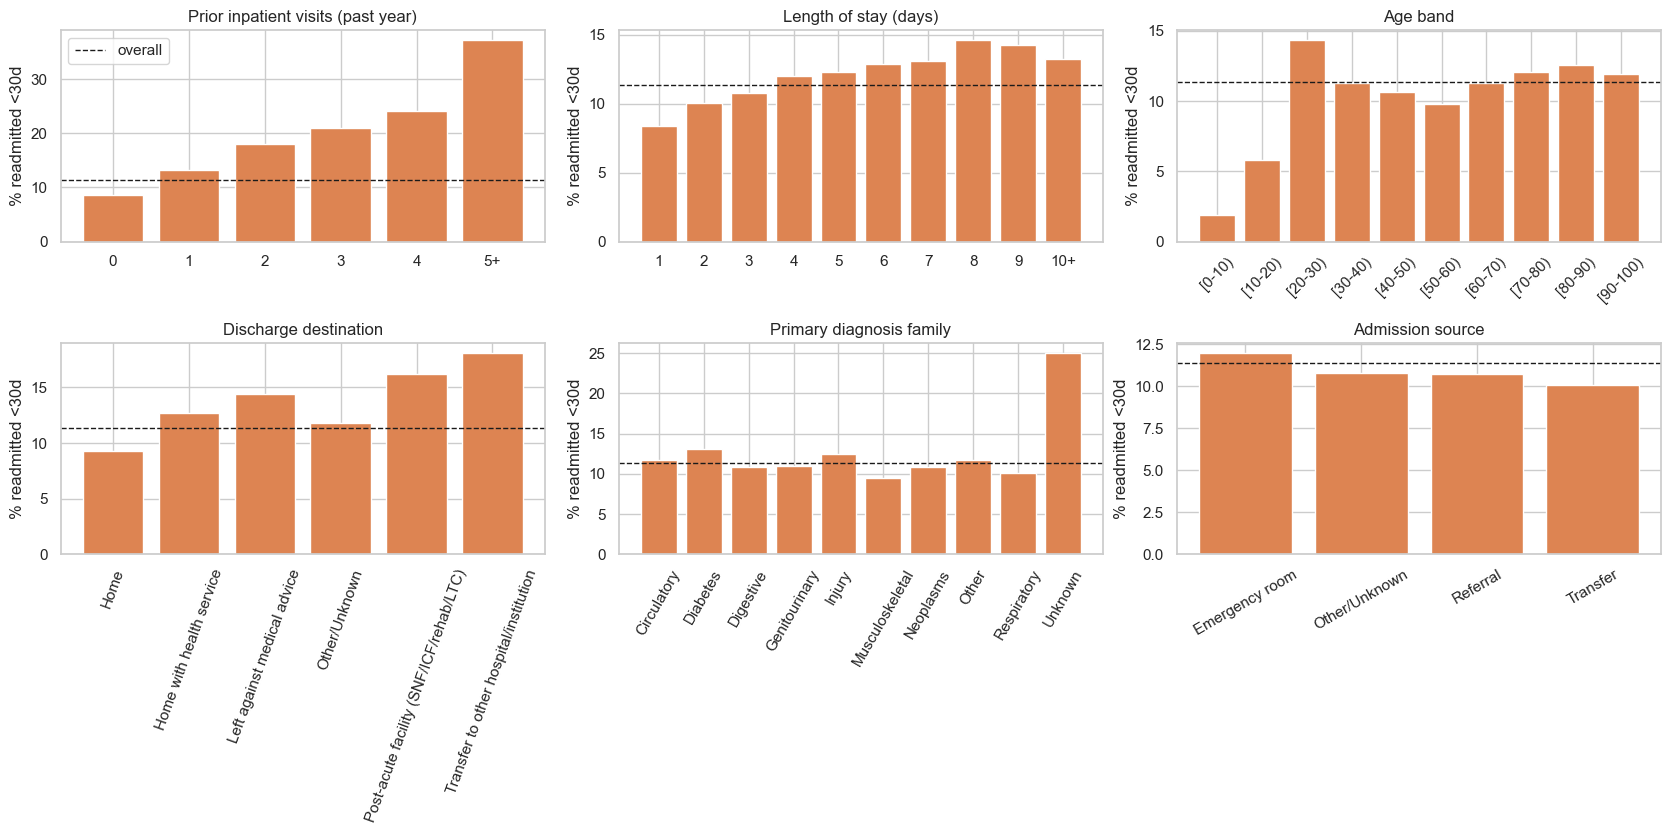

In [24]:
def rate_plot(ax, col, order=None, title=None, rotate=0):
    r = df.groupby(col)["target"].agg(["mean", "size"])
    if order is not None: r = r.reindex(order)
    ax.bar(r.index.astype(str), r["mean"]*100, color="#DD8452")
    ax.axhline(df["target"].mean()*100, color="k", ls="--", lw=1, label="overall")
    ax.set_title(title or col); ax.set_ylabel("% readmitted <30d"); ax.tick_params(axis="x", rotation=rotate)

df["inpatient_cap"] = df["number_inpatient"].clip(upper=5).astype(str).replace({"5": "5+"})
df["los_cap"] = df["time_in_hospital"].clip(upper=10).astype(str).replace({"10": "10+"})

fig, axes = plt.subplots(2, 3, figsize=(17, 8.5))
rate_plot(axes[0,0], "inpatient_cap", ["0","1","2","3","4","5+"], "Prior inpatient visits (past year)")
rate_plot(axes[0,1], "los_cap", [str(i) for i in range(1,10)]+["10+"], "Length of stay (days)")
rate_plot(axes[0,2], "age", None, "Age band", rotate=45)
rate_plot(axes[1,0], "discharge_group", None, "Discharge destination", rotate=70)
rate_plot(axes[1,1], "diag_1_grp", None, "Primary diagnosis family", rotate=60)
rate_plot(axes[1,2], "admission_source", None, "Admission source", rotate=30)
axes[0,0].legend(); plt.tight_layout(); plt.show()
df.drop(columns=["inpatient_cap", "los_cap"], inplace=True)

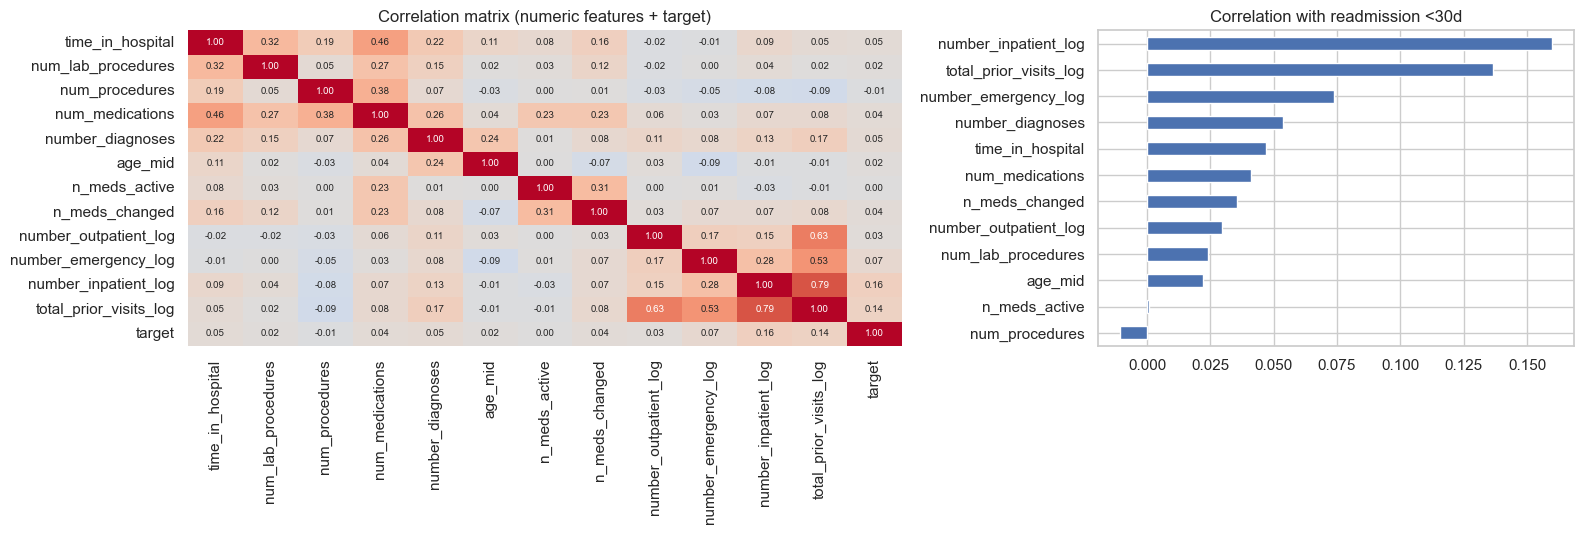

In [25]:
# Correlation of numeric features with the target + among themselves
corr = df[num_cols + ["target"]].corr()
fig, ax = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1.5, 1]})
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax[0], cbar=False, annot_kws={"size": 7})
ax[0].set_title("Correlation matrix (numeric features + target)")
corr["target"].drop("target").sort_values().plot.barh(ax=ax[1], color="#4C72B0")
ax[1].set_title("Correlation with readmission <30d")
plt.tight_layout(); plt.show()

**Findings from exploration**
- Readmission risk **rises steadily with the number of prior inpatient visits** (from under 10 % with none to over 30 % with five or more) and, more gently, with length of stay.
- Risk differs by **discharge destination** and by **primary diagnosis family**, so grouped categorical features are worth keeping.
- Linear correlations with the target are **weak** – the strongest is prior inpatient visits (|r| ≈ 0.17) and everything else is lower. This is a **hard, noisy prediction problem**, so we should expect only moderate ROC-AUC (roughly 0.6–0.7 is typical for this dataset), not near-perfect scores.

## 3.8 Train / validation / test split (stratified **and** grouped by patient)
~70 % train · ~15 % validation · ~15 % test. `StratifiedGroupKFold` keeps the positive rate similar in each set **and** guarantees that no patient appears in more than one set.

In [26]:
X = df[feature_cols].copy()
y = df["target"].copy()
groups = df["patient_nbr"]
ids = df[["encounter_id", "patient_nbr"]].copy()

# test ≈ 1/7 of the data
sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
trainval_idx, test_idx = next(sgkf.split(X, y, groups))
# validation ≈ 1/6 of the remainder
sgkf2 = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=SEED)
tr_rel, va_rel = next(sgkf2.split(X.iloc[trainval_idx], y.iloc[trainval_idx], groups.iloc[trainval_idx]))
train_idx, val_idx = trainval_idx[tr_rel], trainval_idx[va_rel]

X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
X_val,   y_val   = X.iloc[val_idx],   y.iloc[val_idx]
X_test,  y_test  = X.iloc[test_idx],  y.iloc[test_idx]

summary = pd.DataFrame({
    "rows":  [len(X_train), len(X_val), len(X_test)],
    "share_%": [round(100*len(s)/len(X), 1) for s in (X_train, X_val, X_test)],
    "patients": [groups.iloc[i].nunique() for i in (train_idx, val_idx, test_idx)],
    "positive_rate_%": [round(100*s.mean(), 2) for s in (y_train, y_val, y_test)],
}, index=["train", "validation", "test"])
display(summary)

p_tr, p_va, p_te = (set(groups.iloc[i]) for i in (train_idx, val_idx, test_idx))
print("Patients shared between sets (must be 0):", len(p_tr & p_va), len(p_tr & p_te), len(p_va & p_te))

,rows,share_%,patients,positive_rate_%
train,71235,71.7,49974,11.46
validation,14055,14.1,9990,11.47
test,14050,14.1,10023,10.98


Patients shared between sets (must be 0): 0 0 0


## 3.9 Encoding & scaling (fitted on the **training set only**)
- Numeric features → `StandardScaler` (MLPs train poorly on unscaled inputs).
- Categorical features → one-hot encoding; categories rarer than 0.5 % of the training rows are pooled into an "infrequent" bucket, unseen categories at inference time are ignored safely.

In [27]:
preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.005, sparse_output=False), cat_cols),
])
Xtr = preprocess.fit_transform(X_train).astype("float32")   # fit ONLY on train
Xva = preprocess.transform(X_val).astype("float32")
Xte = preprocess.transform(X_test).astype("float32")
ytr, yva, yte = y_train.values, y_val.values, y_test.values

print("Train matrix:", Xtr.shape, "| Val:", Xva.shape, "| Test:", Xte.shape)
print("NaNs in processed train:", int(np.isnan(Xtr).sum()))

Train matrix: (71235, 141) | Val: (14055, 141) | Test: (14050, 141)
NaNs in processed train: 0


---
# Part 4 · MLP Architecture Design & Implementation

| Component | Choice | Reason |
|---|---|---|
| API | `keras.Sequential` | Required; simple stack of layers |
| Hidden layers | `Dense(128, relu)` → `Dense(64, relu)` | ReLU avoids vanishing gradients; two layers are enough for ~100 tabular inputs |
| Regularisation | `Dropout` + L2 weight decay | Tabular medical data is noisy; prevents memorising the training set |
| Output | `Dense(1, sigmoid)` | Outputs P(readmitted < 30 days) |
| Loss | `binary_crossentropy` | Standard for binary probability output |
| Optimizer | `Adam` (lr = 1e-3) | Adaptive, robust default |
| Imbalance | `class_weight` (balanced) | Penalises missing the rare positive class more |
| Metrics | accuracy, precision, recall, ROC-AUC, PR-AUC | Accuracy alone is misleading at 11 % prevalence |
| Callback | `EarlyStopping(monitor="val_auc")` + restore best weights | Stops when validation stops improving → controls overfitting |

In [28]:
def build_mlp(input_dim, hidden=(128, 64), dropout=0.3, l2=1e-4, lr=1e-3):
    reg = keras.regularizers.l2(l2) if l2 else None
    model = keras.Sequential(name="readmission_mlp")
    model.add(layers.Input(shape=(input_dim,)))
    for units in hidden:
        model.add(layers.Dense(units, activation="relu", kernel_regularizer=reg))   # hidden layer with ReLU
        if dropout: model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1, activation="sigmoid"))                                # output: probability
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss="binary_crossentropy",
        metrics=["accuracy",
                 keras.metrics.Precision(name="precision"),
                 keras.metrics.Recall(name="recall"),
                 keras.metrics.AUC(name="auc"),
                 keras.metrics.AUC(name="pr_auc", curve="PR")],
    )
    return model

model_demo = build_mlp(Xtr.shape[1])
model_demo.summary()

Model: "readmission_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        18,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,497 (103.50 KB)

 Trainable params: 26,497 (103.50 KB)

 Non-trainable params: 0 (0.00 B)

---
# Part 5 · Model Training & Evaluation
## 5.1 Class weights

In [29]:
classes = np.array([0, 1])
cw = compute_class_weight("balanced", classes=classes, y=ytr)
class_weight = {0: cw[0], 1: cw[1]}
print("Class weights:", {k: round(v, 3) for k, v in class_weight.items()})

Class weights: {0: np.float64(0.565), 1: np.float64(4.365)}


## 5.2 Experiments – epochs, batch sizes, class weighting, regularisation, depth
Each run trains for up to 40 epochs with early stopping on **validation ROC-AUC**; the best epoch is restored. We compare:
- **batch size** 64 / 256 / 1024 (speed vs. gradient noise),
- **with vs without class weights** (effect of imbalance),
- **with vs without dropout/L2** (effect on generalization),
- **a deeper network**.

Selection uses the **validation** set only; the test set stays untouched.

In [30]:
MAX_EPOCHS = 40
experiments = {
    "A  bs=64   +classwt":            dict(batch=64,   cw=True,  hidden=(128, 64),      dropout=0.3, l2=1e-4),
    "B  bs=256  +classwt":            dict(batch=256,  cw=True,  hidden=(128, 64),      dropout=0.3, l2=1e-4),
    "C  bs=1024 +classwt":            dict(batch=1024, cw=True,  hidden=(128, 64),      dropout=0.3, l2=1e-4),
    "D  bs=256  NO classwt":          dict(batch=256,  cw=False, hidden=(128, 64),      dropout=0.3, l2=1e-4),
    "E  bs=256  +classwt, no reg.":   dict(batch=256,  cw=True,  hidden=(128, 64),      dropout=0.0, l2=0.0),
    "F  bs=256  +classwt, deeper":    dict(batch=256,  cw=True,  hidden=(256, 128, 64), dropout=0.3, l2=1e-4),
}

histories, models, rows = {}, {}, []
for name, cfg in experiments.items():
    tf.keras.utils.set_random_seed(SEED)
    m = build_mlp(Xtr.shape[1], hidden=cfg["hidden"], dropout=cfg["dropout"], l2=cfg["l2"])
    es = keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=5, restore_best_weights=True)
    t0 = time.time()
    h = m.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=MAX_EPOCHS, batch_size=cfg["batch"],
              class_weight=class_weight if cfg["cw"] else None, callbacks=[es], verbose=0)
    secs = time.time() - t0
    best = int(np.argmax(h.history["val_auc"]))
    pva = m.predict(Xva, batch_size=4096, verbose=0).ravel()
    ptr = m.predict(Xtr, batch_size=4096, verbose=0).ravel()
    rows.append({
        "experiment": name, "epochs_run": len(h.history["auc"]), "best_epoch": best + 1,
        "train_auc": roc_auc_score(ytr, ptr), "val_auc": roc_auc_score(yva, pva),
        "auc_gap": roc_auc_score(ytr, ptr) - roc_auc_score(yva, pva),
        "val_recall@0.5": recall_score(yva, pva >= 0.5), "val_precision@0.5": precision_score(yva, pva >= 0.5, zero_division=0),
        "val_pr_auc": average_precision_score(yva, pva), "seconds": round(secs, 1),
    })
    histories[name], models[name] = h.history, m
    print(f"done {name:32s} best_epoch={best+1:2d}  val_auc={rows[-1]['val_auc']:.4f}  ({secs:.0f}s)")

results = pd.DataFrame(rows).set_index("experiment").round(4)
results

done A  bs=64   +classwt              best_epoch= 5  val_auc=0.6758  (44s)
done B  bs=256  +classwt              best_epoch= 7  val_auc=0.6723  (20s)
done C  bs=1024 +classwt              best_epoch= 8  val_auc=0.6736  (12s)
done D  bs=256  NO classwt            best_epoch=10  val_auc=0.6703  (25s)
done E  bs=256  +classwt, no reg.     best_epoch= 4  val_auc=0.6694  (14s)
done F  bs=256  +classwt, deeper      best_epoch= 5  val_auc=0.6722  (128s)


,epochs_run,best_epoch,train_auc,val_auc,auc_gap,val_recall@0.5,val_precision@0.5,val_pr_auc,seconds
experiment,,,,,,,,,
A bs=64 +classwt,10,5,0.6940,0.6758,0.0182,0.6749,0.1736,0.2152,44.3
B bs=256 +classwt,12,7,0.7040,0.6723,0.0317,0.6445,0.1745,0.2143,20.0
C bs=1024 +classwt,13,8,0.7002,0.6736,0.0265,0.6811,0.1680,0.2177,12.5
D bs=256 NO classwt,15,10,0.7042,0.6703,0.0339,0.0087,0.7000,0.2140,24.7
"E bs=256 +classwt, no reg.",9,4,0.7129,0.6694,0.0435,0.6886,0.1664,0.2129,14.0
"F bs=256 +classwt, deeper",10,5,0.6927,0.6722,0.0205,0.6967,0.1664,0.2149,128.4


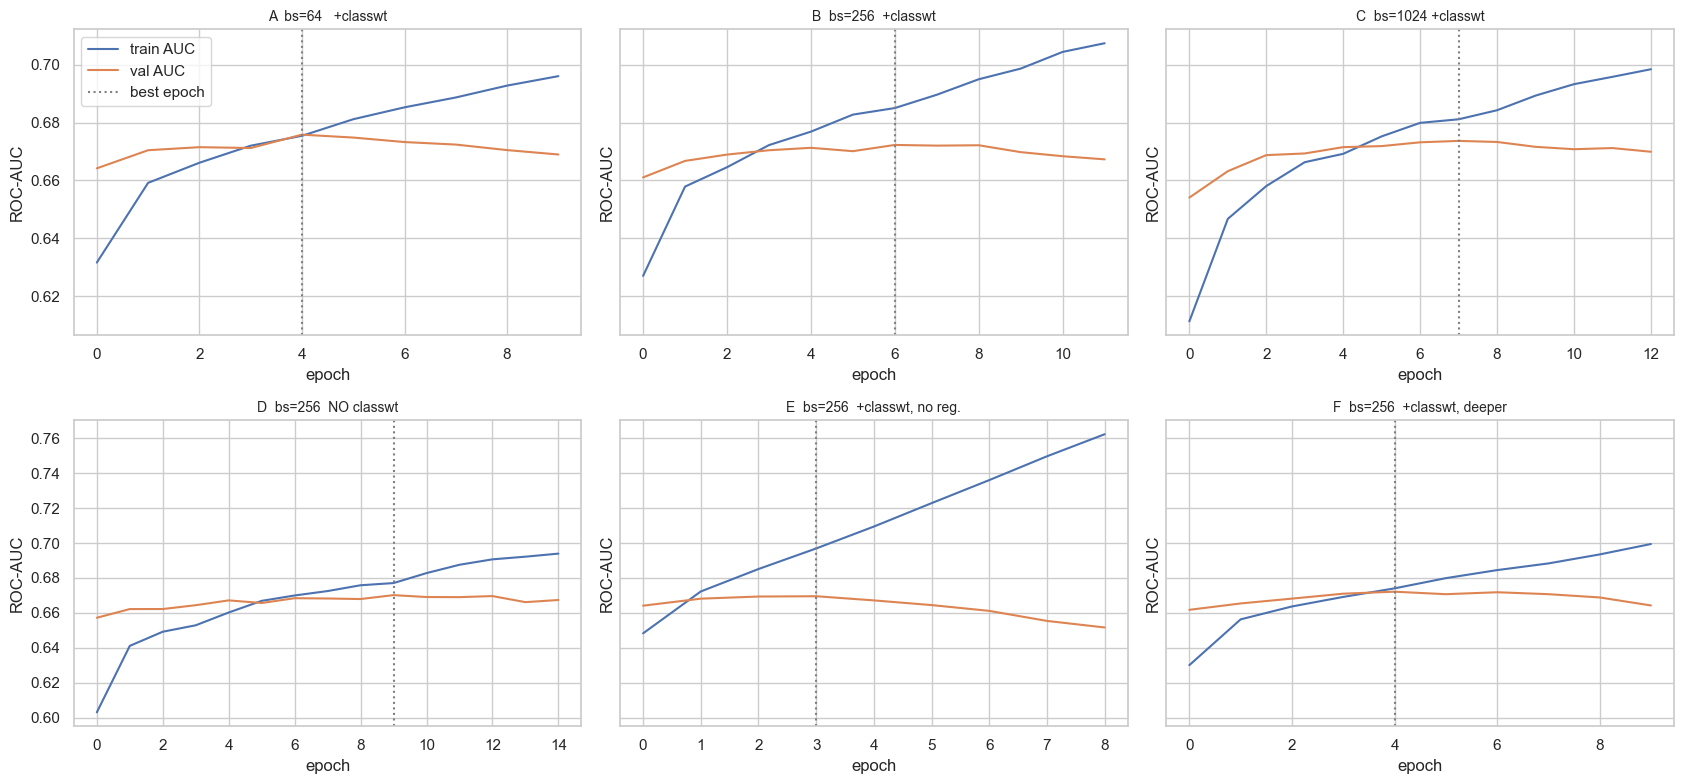

In [31]:
# Learning curves for every experiment
fig, axes = plt.subplots(2, 3, figsize=(17, 8), sharey="row")
for ax, (name, h) in zip(axes.ravel(), histories.items()):
    ax.plot(h["auc"], label="train AUC"); ax.plot(h["val_auc"], label="val AUC")
    ax.axvline(int(np.argmax(h["val_auc"])), color="grey", ls=":", label="best epoch")
    ax.set_title(name, fontsize=10); ax.set_xlabel("epoch"); ax.set_ylabel("ROC-AUC")
axes[0,0].legend(); plt.tight_layout(); plt.show()

**How to read this (generalization check and experiments):**
- **Batch size and depth barely change ranking quality** – validation ROC-AUC differs only in the third decimal place across runs A–F, which is within run-to-run noise. The main practical effect of batch size is **training time** (batch 64 is several times slower than 256/1024).
- **Regularisation changes *when* the model overfits.** Run **E** (no dropout/L2) reaches its best validation AUC after only ~2 epochs and then starts to degrade, whereas the regularised runs keep improving for longer (see "best_epoch" and the learning curves). `EarlyStopping` with restored weights keeps every run's final train–validation gap modest (a few AUC points), so none is badly overfitted.
- **Class weights do not improve ranking, they change the operating point.** Run **D** (no class weights) has a similar ROC-AUC to the weighted runs, but its recall at the default 0.5 threshold is close to zero because the model almost never predicts the minority class. This is the practical impact of class imbalance.
- Because differences in AUC are tiny, we select the run with the best validation AUC but treat the architecture choice as **not critical**; the threshold and class weighting matter far more.

## 5.3 Select the final model (by validation ROC-AUC) and check generalization

Selected experiment: A  bs=64   +classwt


,ROC-AUC,PR-AUC
train,0.6940,0.2417
validation,0.6758,0.2152
gap (train − val),0.0182,0.0265


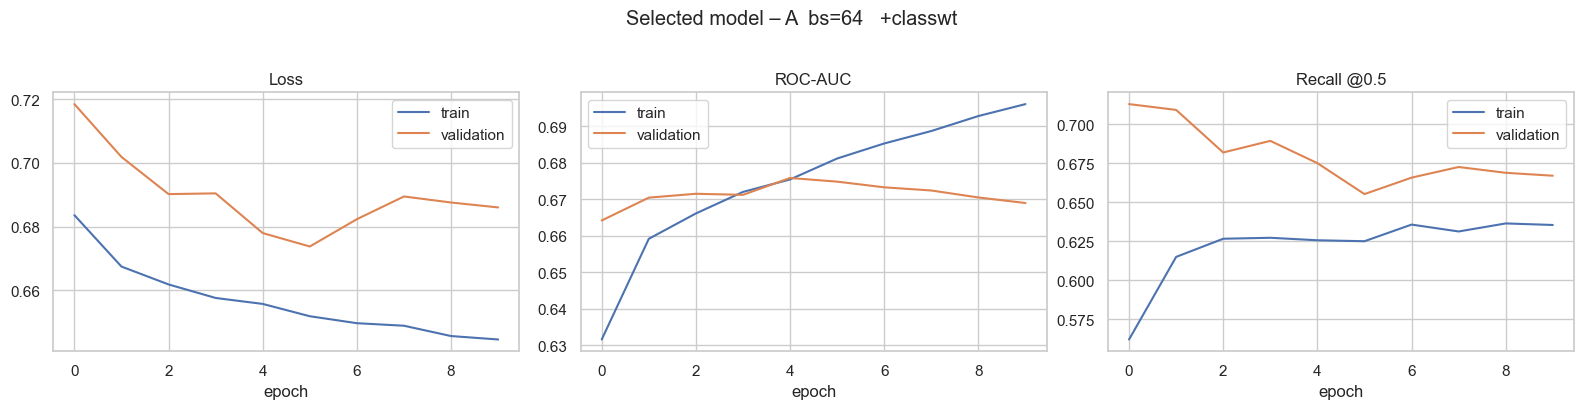

In [32]:
best_name = results["val_auc"].idxmax()
model = models[best_name]
print("Selected experiment:", best_name)

p_tr = model.predict(Xtr, batch_size=4096, verbose=0).ravel()
p_va = model.predict(Xva, batch_size=4096, verbose=0).ravel()

gen = pd.DataFrame({
    "ROC-AUC": [roc_auc_score(ytr, p_tr), roc_auc_score(yva, p_va)],
    "PR-AUC":  [average_precision_score(ytr, p_tr), average_precision_score(yva, p_va)],
}, index=["train", "validation"]).round(4)
gen.loc["gap (train − val)"] = (gen.loc["train"] - gen.loc["validation"]).round(4)
display(gen)

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
h = histories[best_name]
ax[0].plot(h["loss"], label="train"); ax[0].plot(h["val_loss"], label="validation"); ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(h["auc"], label="train"); ax[1].plot(h["val_auc"], label="validation"); ax[1].set_title("ROC-AUC"); ax[1].legend()
ax[2].plot(h["recall"], label="train"); ax[2].plot(h["val_recall"], label="validation"); ax[2].set_title("Recall @0.5"); ax[2].legend()
for a in ax: a.set_xlabel("epoch")
plt.suptitle(f"Selected model – {best_name}", y=1.02); plt.tight_layout(); plt.show()

## 5.4 Choosing the decision threshold (on the validation set)
The network outputs a probability; **0.5 is not sacred**. Because missing a high-risk patient is costlier than a false alarm, we look at the precision/recall trade-off on the **validation** set and compare operating points:
- **0.5** – the default,
- **F1-optimal** – best balance of precision and recall,
- **F2-optimal (unconstrained)** – weights recall twice as much as precision, matching the asymmetric business cost, **but** it may flag so many patients that nobody could follow them all up,
- **F2-optimal within follow-up capacity** – the same recall-weighted score, restricted to thresholds that flag no more than `CAPACITY` of patients. **This is our final choice**, because a risk model is only useful if the alert list is small enough for the hospital to act on.

,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc,flagged_%
model,,,,,,,,
default 0.5,0.500,0.594,0.174,0.675,0.276,0.676,0.215,44.603
F1-optimal,0.574,0.714,0.202,0.507,0.289,0.676,0.215,28.801
F2-optimal (unconstrained),0.448,0.504,0.159,0.778,0.265,0.676,0.215,55.994
F2-optimal within capacity (<= 40% flagged),0.525,0.636,0.181,0.620,0.281,0.676,0.215,39.189


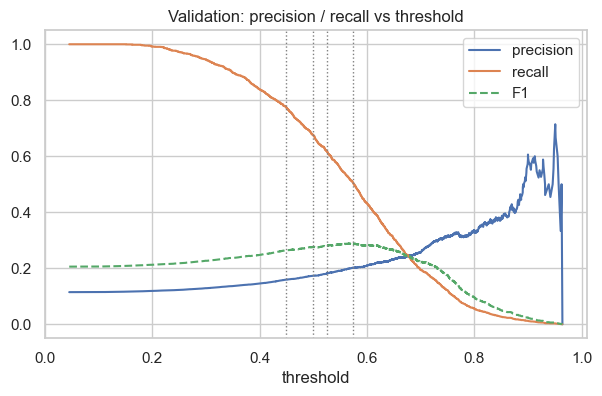

In [33]:
prec, rec, thr = precision_recall_curve(yva, p_va)
f1 = 2*prec*rec / (prec + rec + 1e-12)
f2 = 5*prec*rec / (4*prec + rec + 1e-12)
thr_f1 = float(thr[np.argmax(f1[:-1])])
thr_f2 = float(thr[np.argmax(f2[:-1])])

def evaluate(y_true, p, t, name):
    pred = (p >= t).astype(int)
    return {"model": name, "threshold": round(float(t), 3),
            "accuracy": accuracy_score(y_true, pred), "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred), "f1": f1_score(y_true, pred),
            "roc_auc": roc_auc_score(y_true, p), "pr_auc": average_precision_score(y_true, p),
            "flagged_%": 100*pred.mean()}

# Follow-up capacity: the share of discharged patients the care team can realistically contact (edit to your hospital)
CAPACITY = 0.40

def pick_threshold(y_true, p, capacity=CAPACITY):
    # Threshold maximising F2 among thresholds that flag <= `capacity` of patients (validation data only)
    pr, rc, th = precision_recall_curve(y_true, p)
    f2_ = 5*pr[:-1]*rc[:-1] / (4*pr[:-1] + rc[:-1] + 1e-12)
    flagged = np.array([(p >= t).mean() for t in th])
    ok = flagged <= capacity
    return float(th[ok][np.argmax(f2_[ok])])

thr_cap = pick_threshold(yva, p_va)

ops = pd.DataFrame([evaluate(yva, p_va, 0.5, "default 0.5"),
                    evaluate(yva, p_va, thr_f1, "F1-optimal"),
                    evaluate(yva, p_va, thr_f2, "F2-optimal (unconstrained)"),
                    evaluate(yva, p_va, thr_cap, f"F2-optimal within capacity (<= {CAPACITY:.0%} flagged)")]).set_index("model").round(3)
display(ops)

plt.figure(figsize=(7, 4))
plt.plot(thr, prec[:-1], label="precision"); plt.plot(thr, rec[:-1], label="recall"); plt.plot(thr, f1[:-1], label="F1", ls="--")
for t, lab in [(0.5, "0.5"), (thr_f1, "F1-opt"), (thr_f2, "F2-opt"), (thr_cap, "final")]: plt.axvline(t, color="grey", ls=":", lw=1)
plt.xlabel("threshold"); plt.title("Validation: precision / recall vs threshold"); plt.legend(); plt.show()

**Business reading.** Raising recall means flagging more patients (see the `flagged_%` column). The unconstrained F2 threshold flags well over half of all patients – too many to follow up. Hospitals have limited capacity, so for the formal evaluation below we adopt the **capacity-constrained, recall-oriented threshold** chosen on validation data. Part 7 then ranks patients into **risk tiers** so the scarcest resources go to the very highest-risk patients first.

In [34]:
FINAL_THRESHOLD = thr_cap
FINAL_KEY = "MLP @ final threshold (capacity-constrained F2)"
print(f"Final operating threshold (from validation): {FINAL_THRESHOLD:.3f}")

Final operating threshold (from validation): 0.525


## 5.5 Final evaluation on the held-out **test** set

In [35]:
p_te = model.predict(Xte, batch_size=4096, verbose=0).ravel()

# Reference baselines
dummy_p = np.full_like(p_te, ytr.mean())
lr = LogisticRegression(max_iter=2000, class_weight="balanced").fit(Xtr, ytr)
p_te_lr = lr.predict_proba(Xte)[:, 1]
p_va_lr = lr.predict_proba(Xva)[:, 1]
thr_lr = pick_threshold(yva, p_va_lr)

test_table = pd.DataFrame([
    evaluate(yte, np.zeros_like(p_te), 0.5, "Baseline: always 'No'"),
    evaluate(yte, p_te_lr, thr_lr, "Logistic regression (class-balanced, same threshold rule)"),
    evaluate(yte, p_te, 0.5, "MLP @ 0.5"),
    evaluate(yte, p_te, thr_f1, "MLP @ F1-optimal threshold"),
    evaluate(yte, p_te, thr_f2, "MLP @ unconstrained F2 threshold"),
    evaluate(yte, p_te, FINAL_THRESHOLD, FINAL_KEY),
]).set_index("model")
test_table.loc["Baseline: always 'No'", ["roc_auc", "pr_auc"]] = [0.5, yte.mean()]
display(test_table.round(3))

,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc,flagged_%
model,,,,,,,,
Baseline: always 'No',0.500,0.890,0.000,0.000,0.000,0.500,0.110,0.000
"Logistic regression (class-balanced, same threshold rule)",0.487,0.624,0.161,0.577,0.252,0.649,0.192,39.295
MLP @ 0.5,0.500,0.589,0.159,0.641,0.255,0.656,0.196,44.214
MLP @ F1-optimal threshold,0.574,0.710,0.184,0.477,0.265,0.656,0.196,28.463
MLP @ unconstrained F2 threshold,0.448,0.500,0.147,0.740,0.245,0.656,0.196,55.281
MLP @ final threshold (capacity-constrained F2),0.525,0.632,0.168,0.595,0.262,0.656,0.196,38.883


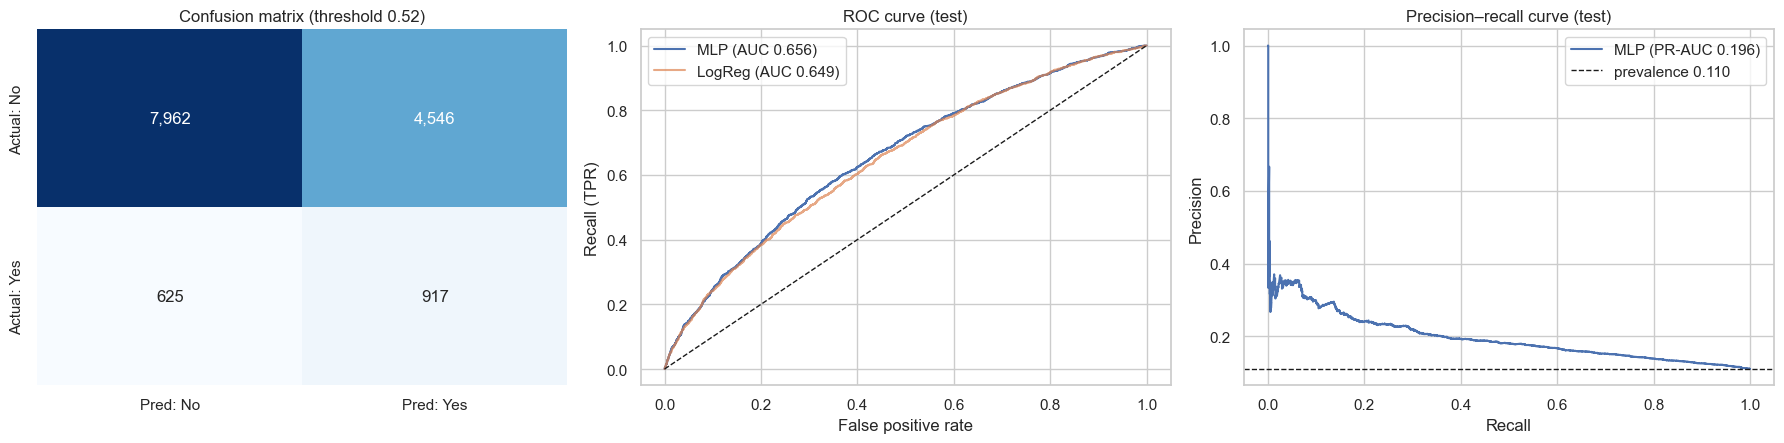

TN=7,962  FP=4,546  FN=625  TP=917


In [36]:
pred_te = (p_te >= FINAL_THRESHOLD).astype(int)
cm = confusion_matrix(yte, pred_te)
tn, fp, fn, tp = cm.ravel()

fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax[0],
            xticklabels=["Pred: No", "Pred: Yes"], yticklabels=["Actual: No", "Actual: Yes"])
ax[0].set_title(f"Confusion matrix (threshold {FINAL_THRESHOLD:.2f})")

fpr, tpr, _ = roc_curve(yte, p_te); fpr_l, tpr_l, _ = roc_curve(yte, p_te_lr)
ax[1].plot(fpr, tpr, label=f"MLP (AUC {roc_auc_score(yte, p_te):.3f})")
ax[1].plot(fpr_l, tpr_l, label=f"LogReg (AUC {roc_auc_score(yte, p_te_lr):.3f})", alpha=.7)
ax[1].plot([0, 1], [0, 1], "k--", lw=1); ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("Recall (TPR)")
ax[1].set_title("ROC curve (test)"); ax[1].legend()

pr_, rc_, _ = precision_recall_curve(yte, p_te)
ax[2].plot(rc_, pr_, label=f"MLP (PR-AUC {average_precision_score(yte, p_te):.3f})")
ax[2].axhline(yte.mean(), color="k", ls="--", lw=1, label=f"prevalence {yte.mean():.3f}")
ax[2].set_xlabel("Recall"); ax[2].set_ylabel("Precision"); ax[2].set_title("Precision–recall curve (test)"); ax[2].legend()
plt.tight_layout(); plt.show()

print(f"TN={tn:,}  FP={fp:,}  FN={fn:,}  TP={tp:,}")

**Interpretation of the results**
- **ROC-AUC / PR-AUC** measure how well the model *ranks* patients independent of any threshold. PR-AUC should be compared with the prevalence (the PR-AUC of a random model), not with 0.5.
- **Accuracy is lower than the "always No" baseline by design** – a recall-oriented threshold deliberately flags many patients to catch more true readmissions, and the "always No" model catches none. This is exactly why accuracy is the wrong headline metric here.
- Moving the threshold trades **recall against precision and workload** (`flagged_%`): flagging more patients catches more readmissions but produces many more false alarms.
- The MLP is compared with a **logistic-regression baseline**: for tabular data of this kind, an MLP often performs similarly to a linear model; the added value of the MLP is evaluated honestly rather than assumed.
- Overall discrimination is **moderate** – consistent with published work on this dataset – because readmission also depends on factors not in the data (social support, adherence, post-discharge care).

---
# Part 6 · Structured Error Analysis
We examine **False Negatives (FN)** – readmitted patients the model missed (most costly) – and **False Positives (FP)** – patients flagged but not readmitted (cost: wasted follow-up effort).

outcome
TP     917
FP    4546
FN     625
TN    7962

Missed readmissions (FN): 625 of 1,542 actual positives = 40.5% miss rate
False alarms (FP): 4,546 of 5,463 flagged = 83.2% of flags are false alarms


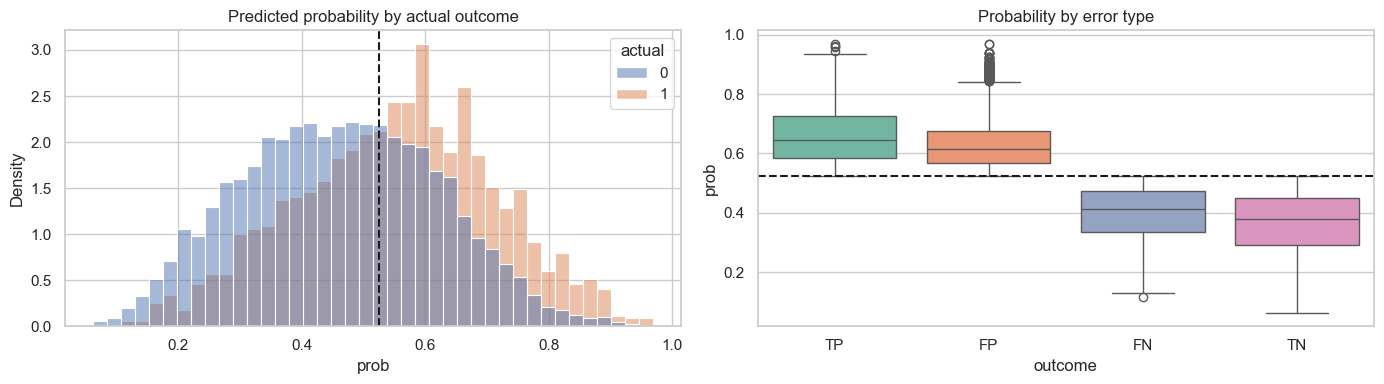

In [37]:
test_df = X_test.copy()
test_df["actual"] = yte
test_df["prob"] = p_te
test_df["pred"] = pred_te
test_df["outcome"] = np.select(
    [(test_df.actual == 1) & (test_df.pred == 1), (test_df.actual == 0) & (test_df.pred == 1),
     (test_df.actual == 1) & (test_df.pred == 0)], ["TP", "FP", "FN"], default="TN")

counts = test_df["outcome"].value_counts().reindex(["TP", "FP", "FN", "TN"])
print(counts.to_string())
print(f"\nMissed readmissions (FN): {fn:,} of {fn+tp:,} actual positives = {fn/(fn+tp):.1%} miss rate")
print(f"False alarms (FP): {fp:,} of {fp+tp:,} flagged = {fp/(fp+tp):.1%} of flags are false alarms")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(data=test_df, x="prob", hue="actual", bins=40, stat="density", common_norm=False, ax=ax[0], palette=["#4C72B0", "#DD8452"])
ax[0].axvline(FINAL_THRESHOLD, color="k", ls="--"); ax[0].set_title("Predicted probability by actual outcome")
sns.boxplot(data=test_df, x="outcome", y="prob", order=["TP", "FP", "FN", "TN"], ax=ax[1], palette="Set2")
ax[1].axhline(FINAL_THRESHOLD, color="k", ls="--"); ax[1].set_title("Probability by error type")
plt.tight_layout(); plt.show()

### 6.1 What do the errors look like? (profile of each outcome group)

In [38]:
profile_cols = ["time_in_hospital", "number_inpatient_log", "total_prior_visits_log", "num_medications",
                "number_diagnoses", "num_lab_procedures", "age_mid", "n_meds_changed"]
prof = test_df.groupby("outcome")[profile_cols].mean().reindex(["TP", "FP", "FN", "TN"]).round(2)
prof["n"] = counts
display(prof)

# Raw (un-logged) prior inpatient visits for readability
test_raw = df.loc[X_test.index, ["number_inpatient"]].assign(outcome=test_df["outcome"])
print("\nMean prior inpatient visits by outcome:")
print(test_raw.groupby("outcome")["number_inpatient"].mean().reindex(["TP", "FP", "FN", "TN"]).round(2).to_string())

,time_in_hospital,number_inpatient_log,total_prior_visits_log,num_medications,number_diagnoses,num_lab_procedures,age_mid,n_meds_changed,n
outcome,,,,,,,,,
TP,5.31,0.81,1.03,18.18,7.98,45.94,67.08,0.42,917
FP,5.27,0.65,0.89,17.33,8.03,45.70,68.42,0.35,4546
FN,4.10,0.08,0.26,15.62,7.34,41.53,66.79,0.23,625
TN,3.76,0.07,0.22,14.97,6.99,40.77,63.89,0.24,7962



Mean prior inpatient visits by outcome:
outcome
TP    1.81
FP    1.27
FN    0.12
TN    0.11


### 6.2 Where does the model miss the most? (false-negative rate by segment)

In [39]:
seg = test_df.copy()
seg["prior_inpatient"] = df.loc[seg.index, "number_inpatient"].clip(upper=3).astype(str).replace({"3": "3+"})
seg["discharge_group"] = df.loc[seg.index, "discharge_group"]
seg["age_band"] = df.loc[seg.index, "age"]
seg["primary_dx"] = seg["diag_1_grp"]

def segment_table(col):
    g = seg.groupby(col).apply(lambda d: pd.Series({
        "patients": len(d),
        "readmit_rate_%": 100*d.actual.mean(),
        "recall_%": 100*((d.pred == 1) & (d.actual == 1)).sum() / max(d.actual.sum(), 1),
        "FN_rate_%": 100*((d.pred == 0) & (d.actual == 1)).sum() / max(d.actual.sum(), 1),
        "flagged_%": 100*d.pred.mean(),
    }))
    return g.round(1)

for col in ["prior_inpatient", "discharge_group", "age_band", "primary_dx"]:
    print(f"\n── by {col} ──"); display(segment_table(col))


── by prior_inpatient ──


,patients,readmit_rate_%,recall_%,FN_rate_%,flagged_%
prior_inpatient,,,,,
0,9523.0,8.6,32.1,67.9,19.2
1,2643.0,12.4,81.1,18.9,68.3
2,1006.0,16.8,95.9,4.1,95.5
3+,878.0,25.7,100.0,0.0,99.3



── by discharge_group ──


,patients,readmit_rate_%,recall_%,FN_rate_%,flagged_%
discharge_group,,,,,
Home,8467.0,8.9,44.1,55.9,23.4
Home with health service,1920.0,11.6,55.2,44.8,44.3
Left against medical advice,98.0,11.2,63.6,36.4,38.8
Other/Unknown,657.0,13.2,56.3,43.7,40.0
Post-acute facility (SNF/ICF/rehab/LTC),2586.0,16.2,86.2,13.8,80.9
Transfer to other hospital/institution,322.0,15.8,90.2,9.8,73.0



── by age_band ──


,patients,readmit_rate_%,recall_%,FN_rate_%,flagged_%
age_band,,,,,
[0-10),23.0,4.3,0.0,100.0,0.0
[10-20),91.0,2.2,50.0,50.0,20.9
[20-30),255.0,10.6,66.7,33.3,40.8
[30-40),626.0,12.0,64.0,36.0,33.2
[40-50),1330.0,7.8,49.0,51.0,29.5
[50-60),2242.0,10.6,60.8,39.2,31.4
[60-70),3195.0,11.7,59.8,40.2,37.8
[70-80),3605.0,10.8,59.0,41.0,41.4
[80-90),2290.0,12.9,60.8,39.2,49.3



── by primary_dx ──


,patients,readmit_rate_%,recall_%,FN_rate_%,flagged_%
primary_dx,,,,,
Circulatory,4249.0,10.8,56.8,43.2,41.3
Diabetes,1270.0,12.8,71.2,28.8,45.3
Digestive,1285.0,11.1,61.3,38.7,38.9
Genitourinary,766.0,10.4,60.0,40.0,39.2
Injury,960.0,13.5,73.1,26.9,49.2
Musculoskeletal,709.0,9.7,50.7,49.3,28.5
Neoplasms,432.0,9.0,53.8,46.2,31.2
Other,2492.0,11.2,56.3,43.7,38.6
Respiratory,1887.0,9.6,53.8,46.2,29.9


### 6.3 Subgroup performance (fairness sanity check)

In [40]:
def subgroup_auc(col):
    out = []
    for k, d in test_df.assign(**{col: df.loc[test_df.index, col]}).groupby(col):
        if d.actual.nunique() == 2 and len(d) >= 200:
            out.append({col: k, "n": len(d), "readmit_rate_%": round(100*d.actual.mean(), 1),
                        "ROC-AUC": round(roc_auc_score(d.actual, d.prob), 3),
                        "recall_%": round(100*recall_score(d.actual, d.pred), 1),
                        "flagged_%": round(100*d.pred.mean(), 1)})
    return pd.DataFrame(out).set_index(col)
for col in ["gender", "race"]:
    display(subgroup_auc(col))

,n,readmit_rate_%,ROC-AUC,recall_%,flagged_%
gender,,,,,
Female,7737,11.1,0.651,58.9,39.8
Male,6313,10.9,0.664,60.1,37.8


,n,readmit_rate_%,ROC-AUC,recall_%,flagged_%
race,,,,,
AfricanAmerican,2606,11.2,0.660,62.7,38.7
Caucasian,10520,10.9,0.652,58.8,39.4
Hispanic,294,9.9,0.725,62.1,35.7
Other,228,10.5,0.681,66.7,36.8
Unknown,316,11.4,0.681,50.0,27.8


### 6.4 Most confident mistakes (case-level view)

In [41]:
show_cols = ["time_in_hospital", "num_medications", "number_diagnoses", "diag_1_grp", "prob"]
extra = df.loc[test_df.index, ["encounter_id", "age", "number_inpatient"]]
cases = test_df.join(extra)
print("Highest-confidence FALSE POSITIVES (flagged, but not readmitted):")
display(cases[cases.outcome == "FP"].nlargest(5, "prob")[["encounter_id", "age", "discharge_group", "number_inpatient"] + show_cols].round(3))
print("Lowest-probability FALSE NEGATIVES (readmitted, but model was confident they were safe):")
display(cases[cases.outcome == "FN"].nsmallest(5, "prob")[["encounter_id", "age", "discharge_group", "number_inpatient"] + show_cols].round(3))

Highest-confidence FALSE POSITIVES (flagged, but not readmitted):


,encounter_id,age,discharge_group,number_inpatient,time_in_hospital,num_medications,number_diagnoses,diag_1_grp,prob
97107,413795030,[30-40),Transfer to other hospital/institution,8,3,18,9,Diabetes,0.970
85081,277605918,[30-40),Home,14,1,7,9,Other,0.968
99010,439061744,[30-40),Home,7,5,19,9,Other,0.941
83570,271182900,[30-40),Home,14,14,31,9,Musculoskeletal,0.940
77584,243835206,[30-40),Home,10,1,14,9,Circulatory,0.939


Lowest-probability FALSE NEGATIVES (readmitted, but model was confident they were safe):


,encounter_id,age,discharge_group,number_inpatient,time_in_hospital,num_medications,number_diagnoses,diag_1_grp,prob
24058,82984626,[60-70),Home,0,2,18,5,Respiratory,0.115
52488,157166472,[60-70),Home,0,2,5,2,Musculoskeletal,0.130
71841,217398228,[20-30),Home,0,2,4,3,Diabetes,0.144
71101,213630534,[40-50),Home,0,2,7,5,Respiratory,0.151
37000,117200394,[40-50),Home,0,4,23,4,Other,0.155


### 6.5 Error-analysis conclusions
| Error type | What the analysis shows | Likely root cause | Mitigation |
|---|---|---|---|
| **False negatives** (missed readmissions) | Their profile is almost indistinguishable from true negatives: essentially **no prior inpatient visits**, shorter stays, fewer diagnoses and medications. The false-negative rate is **highest for patients with no prior inpatient visit** and falls to near zero for patients with several. Some primary-diagnosis families (notably neoplasms and respiratory) and discharges **to home** are also missed more often. | The data hold **no information on social support, medication adherence, post-discharge care or lab trends**; a first-time readmission after an uneventful stay is close to unpredictable from administrative data. | Add richer features; give the "Low" tier a cheap universal touch-point (automated call/message); revisit the threshold if capacity allows. |
| **False positives** (false alarms) | They **resemble true positives more than true negatives** – more prior inpatient visits, longer stays, more medications and diagnoses, and they are older on average. They are genuinely complex patients who were not readmitted within 30 days. | Complexity is a risk factor, not a certainty; follow-up may itself have prevented some returns. | Accept a high false-alarm rate given the cost asymmetry, but use **tiers** to ration intensive support. |
| **Class imbalance** | With only ~11 % positives, precision stays low even when recall is decent: most flagged patients are not readmitted. | Base-rate arithmetic | Judge with PR-AUC, lift and tier readmission rates, not accuracy. |
| **Subgroups** | Gender and the two largest race groups perform similarly; the **very small groups (a few hundred patients) show weaker and unstable results**. | Small samples; possible bias | Monitor subgroup performance and collect more data before any real-world use. |

*(Exact figures are in the tables above and regenerate every time the notebook is run.)*

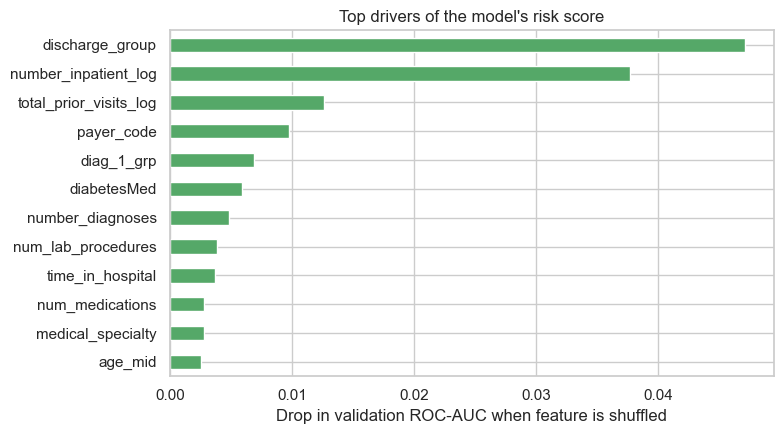

,auc_drop
discharge_group,0.0471
number_inpatient_log,0.0377
total_prior_visits_log,0.0126
payer_code,0.0097
diag_1_grp,0.0069
diabetesMed,0.0059
number_diagnoses,0.0048
num_lab_procedures,0.0039
time_in_hospital,0.0037
num_medications,0.0028


In [42]:
# Which inputs does the model rely on? Permutation importance on the validation set
# (drop in ROC-AUC when one raw feature is shuffled; computed on the full pipeline so one-hot columns are grouped).
def predict_raw(frame):
    return model.predict(preprocess.transform(frame).astype("float32"), batch_size=4096, verbose=0).ravel()

rng = np.random.default_rng(SEED)
sub = X_val.sample(8000, random_state=SEED)
ysub = y_val.loc[sub.index].values
base_auc = roc_auc_score(ysub, predict_raw(sub))
imp = {}
for col in feature_cols:
    drops = []
    for _ in range(3):
        tmp = sub.copy(); tmp[col] = rng.permutation(tmp[col].values)
        drops.append(base_auc - roc_auc_score(ysub, predict_raw(tmp)))
    imp[col] = np.mean(drops)

imp = pd.Series(imp).sort_values(ascending=False)
top = imp.head(12)
plt.figure(figsize=(8, 4.5))
top.iloc[::-1].plot.barh(color="#55A868")
plt.xlabel("Drop in validation ROC-AUC when feature is shuffled"); plt.title("Top drivers of the model's risk score")
plt.tight_layout(); plt.show()
top.round(4).to_frame("auc_drop")

---
# Part 7 · Business Insights & Recommendations
## 7.1 Patient-level prediction report
One row per test-set patient encounter, generated from **our own model** (the identifier is the dataset's `patient_nbr`; `encounter_id` is kept for traceability).

In [43]:
report = pd.DataFrame({
    "Patient ID": "P" + df.loc[X_test.index, "patient_nbr"].astype(str).values,
    "Encounter ID": df.loc[X_test.index, "encounter_id"].values,
    "Actual readmission": np.where(yte == 1, "Yes", "No"),
    "Predicted result": np.where(pred_te == 1, "Yes", "No"),
    "Risk probability": p_te.round(3),
})

# Risk tiers – cut-offs come from the VALIDATION set only (no test information used):
#   High   = top 10% of validation risk scores
#   Medium = above the alert threshold but not High
#   Low    = below the alert threshold
cut_high = np.quantile(p_va, 0.90)
report["Risk tier"] = np.select([report["Risk probability"] >= cut_high, report["Risk probability"] >= FINAL_THRESHOLD],
                                ["High", "Medium"], default="Low")

print("Illustrative sample – 3 examples from each outcome type (TP / FN / FP / TN):")
outcome = test_df["outcome"].values
sample = pd.concat([report[outcome == o].sample(3, random_state=SEED).assign(Outcome=o) for o in ["TP", "FN", "FP", "TN"]])
display(sample.reset_index(drop=True))

print("\nTop 10 highest-risk patients in the test set:")
display(report.sort_values("Risk probability", ascending=False).head(10).reset_index(drop=True))

report.to_csv("readmission_predictions_test.csv", index=False)
print(f"\nFull report ({len(report):,} rows) saved to readmission_predictions_test.csv")

Illustrative sample – 3 examples from each outcome type (TP / FN / FP / TN):


,Patient ID,Encounter ID,Actual readmission,Predicted result,Risk probability,Risk tier,Outcome
0,P87038640,210653184,Yes,Yes,0.576,Medium,TP
1,P13265604,25014474,Yes,Yes,0.690,High,TP
2,P41039298,127166796,Yes,Yes,0.748,High,TP
3,P38739735,217398228,Yes,No,0.144,Low,FN
4,P89378037,245827668,Yes,No,0.382,Low,FN
5,P541755,105846150,Yes,No,0.357,Low,FN
6,P55759554,46695432,No,Yes,0.594,Medium,FP
7,P95770314,265778700,No,Yes,0.674,Medium,FP
8,P5020047,6463974,No,Yes,0.559,Medium,FP
9,P5683158,78363186,No,No,0.320,Low,TN



Top 10 highest-risk patients in the test set:


,Patient ID,Encounter ID,Actual readmission,Predicted result,Risk probability,Risk tier
0,P90489195,413795030,No,Yes,0.970,High
1,P90489195,263115954,Yes,Yes,0.970,High
2,P90489195,277605918,No,Yes,0.968,High
3,P90489195,265100100,Yes,Yes,0.963,High
4,P90489195,259613184,Yes,Yes,0.959,High
5,P90489195,257503632,Yes,Yes,0.945,High
6,P90489195,439061744,No,Yes,0.941,High
7,P90489195,271182900,No,Yes,0.940,High
8,P90489195,243835206,No,Yes,0.939,High
9,P88844373,377878478,No,Yes,0.938,High



Full report (14,050 rows) saved to readmission_predictions_test.csv


## 7.2 How hospitals can prioritise follow-up support
We convert risk scores into **tiers** (cut-offs set on validation data): **High** = top 10 % of risk scores, **Medium** = above the alert threshold but not High, **Low** = below the alert threshold. High + Medium together are the patients the model flags. For each tier we check the *actual* readmission rate and how many of all readmissions it captures.

,patients,readmitted,share_of_patients_%,readmission_rate_%,share_of_all_readmissions_%,lift_vs_average
Risk tier,,,,,,
High,1317,317,9.37,24.07,20.56,2.19
Medium,4151,601,29.54,14.48,38.98,1.32
Low,8582,624,61.08,7.27,40.47,0.66


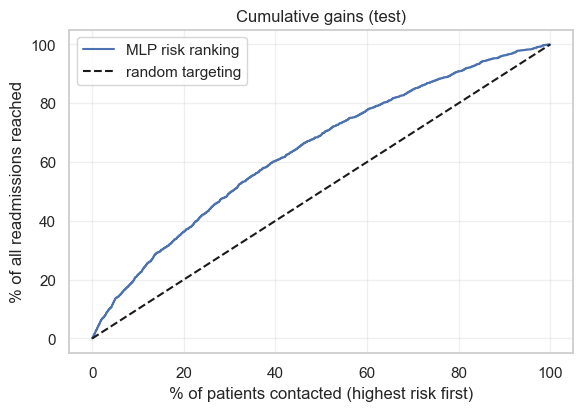

Contacting the top 10% of patients reaches 21.7% of all readmissions (random targeting would reach 10%).
Contacting the top 20% of patients reaches 36.3% of all readmissions (random targeting would reach 20%).
Contacting the top 30% of patients reaches 49.4% of all readmissions (random targeting would reach 30%).


In [44]:
report["actual"] = yte
tier = report.groupby("Risk tier").agg(patients=("actual", "size"), readmitted=("actual", "sum"))
tier = tier.reindex(["High", "Medium", "Low"])
tier["share_of_patients_%"] = 100*tier["patients"]/tier["patients"].sum()
tier["readmission_rate_%"] = 100*tier["readmitted"]/tier["patients"]
tier["share_of_all_readmissions_%"] = 100*tier["readmitted"]/tier["readmitted"].sum()
tier["lift_vs_average"] = tier["readmission_rate_%"] / (100*yte.mean())
display(tier.round(2))

# Cumulative gains: what if follow-up capacity only covers the top X% of patients?
order = np.argsort(-p_te)
cum_capture = np.cumsum(yte[order]) / yte.sum()
x = np.arange(1, len(yte)+1) / len(yte)
plt.figure(figsize=(6.5, 4.2))
plt.plot(x*100, cum_capture*100, label="MLP risk ranking"); plt.plot([0, 100], [0, 100], "k--", label="random targeting")
plt.xlabel("% of patients contacted (highest risk first)"); plt.ylabel("% of all readmissions reached")
plt.title("Cumulative gains (test)"); plt.legend(); plt.grid(alpha=.3); plt.show()
for q in (0.1, 0.2, 0.3):
    k = int(q*len(yte)); print(f"Contacting the top {int(q*100)}% of patients reaches {cum_capture[k-1]:.1%} of all readmissions "
                                f"(random targeting would reach {q:.0%}).")

### Simple economics of intervening (illustrative – replace with your hospital's real figures)
Intervene on a patient group if its readmission probability is above the **break-even rate**

$$ \text{break-even} = \frac{\text{cost of one intervention}}{\text{effectiveness} \times \text{cost of one readmission}} $$

In [45]:
# ⚠ PLACEHOLDER ASSUMPTIONS – not taken from the dataset. Edit to match real hospital data.
COST_READMISSION   = 15000   # average cost of one avoidable readmission (currency units)
COST_INTERVENTION  = 500     # cost of one follow-up package (call + early appointment + med review)
EFFECTIVENESS      = 0.20    # share of would-be readmissions that the intervention prevents

break_even = COST_INTERVENTION / (EFFECTIVENESS * COST_READMISSION)
tier["worth_intervening"] = np.where(tier["readmission_rate_%"] / 100 >= break_even, "Yes", "No")
print(f"Break-even readmission rate: {break_even:.1%}")
display(tier[["patients", "readmission_rate_%", "worth_intervening"]].round(2))

Break-even readmission rate: 16.7%


,patients,readmission_rate_%,worth_intervening
Risk tier,,,
High,1317,24.07,Yes
Medium,4151,14.48,No
Low,8582,7.27,No


In [46]:
from IPython.display import Markdown
m_final = test_table.loc[FINAL_KEY]
m_lr = test_table.loc["Logistic regression (class-balanced, same threshold rule)"]
top3 = ", ".join(f"`{c}`" for c in imp.index[:3])
hi = tier.loc["High"]; lo = tier.loc["Low"]

Markdown(f'''
**Headline results (held-out test set, {len(yte):,} encounters, {yte.mean():.1%} readmitted within 30 days)**

- The MLP ranks patients with **ROC-AUC {m_final.roc_auc:.3f}** (PR-AUC {m_final.pr_auc:.3f} vs. a {yte.mean():.3f} random baseline); the logistic-regression baseline scores {m_lr.roc_auc:.3f}.
- At the chosen alert threshold ({FINAL_THRESHOLD:.2f}, limited to a follow-up capacity of {CAPACITY:.0%} of patients) the model **catches {m_final.recall:.0%} of readmissions** with precision {m_final.precision:.0%}, flagging {m_final["flagged_%"]:.0f}% of patients. Accuracy ({m_final.accuracy:.0%}) is deliberately not the goal.
- The **High-risk tier** ({hi["share_of_patients_%"]:.0f}% of patients) has a readmission rate of **{hi["readmission_rate_%"]:.1f}%** – **{hi.lift_vs_average:.1f}× the average** – and contains {hi["share_of_all_readmissions_%"]:.0f}% of all readmissions. The Low tier's rate is {lo["readmission_rate_%"]:.1f}%.
- The strongest drivers of the risk score are {top3}.
- Generalization: train–validation ROC-AUC gap is {gen.loc["gap (train − val)", "ROC-AUC"]:.3f}, so the selected model is not badly overfitted.
- Class imbalance matters: without class weights the same network barely predicts the minority class at the 0.5 threshold (recall {results.loc[[i for i in results.index if i.startswith('D')][0], 'val_recall@0.5']:.0%} on validation, experiment D).
''')


**Headline results (held-out test set, 14,050 encounters, 11.0% readmitted within 30 days)**

- The MLP ranks patients with **ROC-AUC 0.656** (PR-AUC 0.196 vs. a 0.110 random baseline); the logistic-regression baseline scores 0.649.
- At the chosen alert threshold (0.52, limited to a follow-up capacity of 40% of patients) the model **catches 59% of readmissions** with precision 17%, flagging 39% of patients. Accuracy (63%) is deliberately not the goal.
- The **High-risk tier** (9% of patients) has a readmission rate of **24.1%** – **2.2× the average** – and contains 21% of all readmissions. The Low tier's rate is 7.3%.
- The strongest drivers of the risk score are `discharge_group`, `number_inpatient_log`, `total_prior_visits_log`.
- Generalization: train–validation ROC-AUC gap is 0.018, so the selected model is not badly overfitted.
- Class imbalance matters: without class weights the same network barely predicts the minority class at the 0.5 threshold (recall 1% on validation, experiment D).


### Recommendations

1. **Tiered post-discharge programme.** 
   - **High tier:** nurse/care-coordinator call within 48 h, follow-up appointment booked *before* discharge, medication reconciliation, home-health referral where appropriate.
   - **Medium tier:** lighter-touch, lower-cost contact (scheduled call or nurse-line outreach, clear written discharge instructions with teach-back). Under the placeholder economics in 7.2 the full care package does not break even for this tier, so use cheaper contact methods.
   - **Low tier:** automated reminders / patient portal message – low cost, still covers the false-negative leakage.
2. **Prioritise on prior utilisation and discharge context.** The permutation-importance chart shows the model relies most on the **discharge destination** and **prior inpatient visits**, so patients discharged to facilities or home health, and those with repeated recent admissions, are the natural first targets.
3. **Use discharge planning to review the diabetes regimen.** Diabetes-medication variables (e.g. whether a diabetes medication was prescribed, metformin) appear among the drivers, so medication reconciliation and patient education at discharge are sensible, actionable levers. The model shows association, not causation.
4. **Match the threshold to capacity and cost.** Re-tune the threshold (or tier cut-offs) with the hospital's real cost of a readmission versus the cost of an intervention; the break-even calculation in 7.2 shows how.
5. **Improve the data, not just the model.** Add social-determinant, adherence, lab-trend and clinical-note features; discharge-time vitals; community follow-up data – the error analysis shows missed cases look "ordinary" in the current features.
6. **Governance before any real use.** Re-train on recent data, validate prospectively with clinicians, audit performance by subgroup (race, gender, age, insurance), monitor drift, and keep a human in the loop. Race/payer variables are included here for completeness of the educational exercise and should be reviewed for fairness before operational use.

### Limitations
- Data are from **1999–2008 US hospitals** – practice patterns, coding (ICD-9) and populations have changed.
- Multiple encounters per patient are included (split is patient-grouped, but within-patient correlation remains in training).
- Moderate discrimination: the model supports **prioritisation**, not diagnosis, and is an **educational prototype, not a clinically validated system**.
- Cost figures in 7.2 are placeholders.

---
**Deliverables produced:** this executable notebook · model evaluation results (Part 5) · structured error analysis (Part 6) · patient-level prediction report (`readmission_predictions_test.csv`) · short business findings report (Section 7.3 and recommendations).